# TRUSTSR Final Capstone Lab — Adaptive Recovery, Evidence Concordance & Trust Reinstatement
**Lab 12 | Version 1.0.0 | Evidence class: Synthetic simulation**

## Capstone objective
Build and test an end-to-end, auditable pipeline:

**Attack → Detection → Classification → Recovery → Verification Engine → Trusted State**

This capstone makes the pipeline more rigorous by preserving an evidence ledger, distinguishing detected compromise from confirmed compromise, using a fail-closed recovery gate, and preventing direct promotion from `Contaminated` or `Unknown` to `Trusted`.

## What makes this design distinctive
The contribution tested here is not a claim of being “the first in the world.” It is a concrete, reproducible combination of:
- attack-event simulation with explicit ground truth;
- detection and uncertainty-aware classification;
- selective recovery from a declared trusted checkpoint;
- four-gate recovery verification;
- guarded trust-state transitions;
- end-to-end audit and CSV export.

**Novelty boundary:** This notebook does not establish worldwide novelty. That requires a systematic literature review and comparison with existing recovery, provenance, agent-security, and state-machine verification methods.

## Evidence boundary
Every attack, detection, checkpoint, audit event, recovery action, and outcome in this notebook is synthetic. Assertions demonstrate conformance to the policy implemented here, not production security, cryptographic authenticity, or formal verification.

## 1. Imports and reproducible synthetic scenario

In [1]:
from pathlib import Path
from copy import deepcopy
from datetime import datetime, timezone
import hashlib, json
import pandas as pd
import matplotlib.pyplot as plt

RUN_UTC = datetime.now(timezone.utc).isoformat()
TX_ID = "SYNTH-CAPSTONE-TX-001"
SEED = 20261011

# Ground truth is deliberately explicit and separate from detector output.
GROUND_TRUTH = {
    "known_attack_event_ids": {"EVT-003"},
    "contaminated_artifacts": {"memory_M3"},
    "clean_artifacts": {"memory_M1", "memory_M2"},
    "trusted_checkpoint_id": "CKPT-CLEAN-001",
    "target_version": "agent-state-v8",
}
print("Run UTC:", RUN_UTC)
print("Evidence class: synthetic simulation")
print("Ground-truth attack events:", sorted(GROUND_TRUTH["known_attack_event_ids"]))

Run UTC: 2026-10-11T10:27:43.280682+00:00
Evidence class: synthetic simulation
Ground-truth attack events: ['EVT-003']


## 2. Stage A — Attack simulation

In [2]:
events = [
    {"event_id":"EVT-001", "artifact":"memory_M1", "event_type":"memory_read", "source":"trusted_user", "suspicious":False},
    {"event_id":"EVT-002", "artifact":"memory_M2", "event_type":"memory_write", "source":"trusted_tool", "suspicious":False},
    {"event_id":"EVT-003", "artifact":"memory_M3", "event_type":"memory_write", "source":"untrusted_document", "suspicious":True},
    {"event_id":"EVT-004", "artifact":"memory_M3", "event_type":"memory_reuse", "source":"agent_context", "suspicious":True},
]
event_df = pd.DataFrame(events)
event_df["evidence_classification"] = "synthetic attack trace"
display(event_df)
assert set(event_df["event_id"]) >= GROUND_TRUTH["known_attack_event_ids"]
print("Attack stage: synthetic malicious memory write and subsequent reuse recorded.")

  event_id   artifact    event_type              source  suspicious evidence_classification
0  EVT-001  memory_M1   memory_read        trusted_user       False  synthetic attack trace
1  EVT-002  memory_M2  memory_write        trusted_tool       False  synthetic attack trace
2  EVT-003  memory_M3  memory_write  untrusted_document        True  synthetic attack trace
3  EVT-004  memory_M3  memory_reuse       agent_context        True  synthetic attack trace

Attack stage: synthetic malicious memory write and subsequent reuse recorded.


## 3. Stage B — Detection

In [3]:
def detect_events(event_records):
    detected = []
    for event in event_records:
        # Synthetic detector rule: suspicious flag OR an untrusted source writing memory.
        hit = bool(event["suspicious"]) or (
            event["event_type"] == "memory_write" and event["source"] == "untrusted_document"
        )
        detected.append({
            "event_id": event["event_id"],
            "artifact": event["artifact"],
            "detected": hit,
            "detector_reason": "synthetic_rule_match" if hit else "no_rule_match",
            "evidence_classification": "synthetic detector output",
        })
    return pd.DataFrame(detected)

detection_df = detect_events(events)
display(detection_df)
truth_ids = GROUND_TRUTH["known_attack_event_ids"]
detected_ids = set(detection_df.loc[detection_df["detected"], "event_id"])
tp = len(truth_ids & detected_ids)
fn = len(truth_ids - detected_ids)
fp = len(detected_ids - truth_ids)
print({"TP":tp, "FN":fn, "FP":fp, "synthetic_ground_truth_attack_events":len(truth_ids)})
assert fn == 0, "The fixture is designed so the detector rule catches the declared attack event."
# This is a designed fixture result, not an estimate of real-world detector performance.

  event_id   artifact  detected       detector_reason    evidence_classification
0  EVT-001  memory_M1     False         no_rule_match  synthetic detector output
1  EVT-002  memory_M2     False         no_rule_match  synthetic detector output
2  EVT-003  memory_M3      True  synthetic_rule_match  synthetic detector output
3  EVT-004  memory_M3      True  synthetic_rule_match  synthetic detector output

{'TP': 1, 'FN': 0, 'FP': 1, 'synthetic_ground_truth_attack_events': 1}


## 4. Stage C — Uncertainty-aware classification

In [4]:
def classify_artifacts(event_records, detection_results):
    detected_artifacts = set(detection_results.loc[detection_results["detected"], "artifact"])
    untrusted_writers = {
        e["artifact"] for e in event_records
        if e["event_type"] == "memory_write" and e["source"] == "untrusted_document"
    }
    rows = []
    for artifact in sorted(GROUND_TRUTH["clean_artifacts"] | GROUND_TRUTH["contaminated_artifacts"] | {"memory_M4"}):
        if artifact in untrusted_writers:
            state, reason = "Contaminated", "untrusted source wrote artifact"
        elif artifact in detected_artifacts:
            state, reason = "Suspect", "detector signal without confirmed write provenance"
        elif artifact in GROUND_TRUTH["clean_artifacts"]:
            state, reason = "Trusted", "synthetic fixture declares artifact clean"
        else:
            state, reason = "Unknown", "no sufficient provenance evidence"
        rows.append({"artifact":artifact, "classification":state, "reason":reason,
                     "evidence_classification":"synthetic classification"})
    return pd.DataFrame(rows)

classification_df = classify_artifacts(events, detection_df)
display(classification_df)
assert classification_df.set_index("artifact").loc["memory_M3", "classification"] == "Contaminated"
assert classification_df.set_index("artifact").loc["memory_M4", "classification"] == "Unknown"
print("Classification stage completed; unknown is not treated as trusted.")

    artifact classification                                     reason   evidence_classification
0  memory_M1        Trusted  synthetic fixture declares artifact clean  synthetic classification
1  memory_M2        Trusted  synthetic fixture declares artifact clean  synthetic classification
2  memory_M3   Contaminated            untrusted source wrote artifact  synthetic classification
3  memory_M4        Unknown          no sufficient provenance evidence  synthetic classification

Classification stage completed; unknown is not treated as trusted.


## 5. Stage D — Selective recovery from a declared trusted checkpoint

In [5]:
checkpoint_payload = {
    "checkpoint_id": GROUND_TRUTH["trusted_checkpoint_id"],
    "transaction_id": TX_ID,
    "provenance": "trusted-synthetic-source",
    "target_version": GROUND_TRUTH["target_version"],
    "artifacts": sorted(GROUND_TRUTH["clean_artifacts"]),
}
def digest(payload):
    return hashlib.sha256(json.dumps(payload, sort_keys=True, separators=(",", ":")).encode()).hexdigest()

checkpoint = {
    "payload": checkpoint_payload,
    "digest": digest(checkpoint_payload),
    "expected_digest": digest(checkpoint_payload),
    "signature_valid": True,   # Synthetic flag only; not real cryptographic verification.
    "provenance_trusted": True,
}
# Recovery deliberately restores only artifacts declared clean in the checkpoint.
recovery_record = {
    "transaction_id": TX_ID,
    "completed": True,
    "target_version": GROUND_TRUTH["target_version"],
    "restored_artifacts": list(checkpoint_payload["artifacts"]),
    "unverified_artifacts": ["memory_M4"],  # Unknown artifact remains quarantined.
}
print("Recovered artifacts:", recovery_record["restored_artifacts"])
print("Quarantined/unverified artifacts:", recovery_record["unverified_artifacts"])
assert not (set(recovery_record["restored_artifacts"]) & GROUND_TRUTH["contaminated_artifacts"])
assert "memory_M4" not in recovery_record["restored_artifacts"]

Recovered artifacts: ['memory_M1', 'memory_M2']
Quarantined/unverified artifacts: ['memory_M4']


## 6. Stage E — Recovery Verification Engine

In [6]:
REQUIRED_EVENTS = ["recovery_started", "checkpoint_restored", "verification_requested"]
audit_events = [
    {"transaction_id":TX_ID, "seq":1, "event":"recovery_started", "checkpoint_id":GROUND_TRUTH["trusted_checkpoint_id"]},
    {"transaction_id":TX_ID, "seq":2, "event":"checkpoint_restored", "checkpoint_id":GROUND_TRUTH["trusted_checkpoint_id"]},
    {"transaction_id":TX_ID, "seq":3, "event":"verification_requested", "checkpoint_id":GROUND_TRUTH["trusted_checkpoint_id"]},
]

def verify_checkpoint(cp):
    p = cp.get("payload", {})
    ok = (
        isinstance(p, dict)
        and digest(p) == cp.get("digest") == cp.get("expected_digest")
        and p.get("transaction_id") == TX_ID
        and cp.get("signature_valid") is True
        and cp.get("provenance_trusted") is True
    )
    return ok, "checkpoint_evidence_valid" if ok else "checkpoint_evidence_invalid"

def verify_audit(log):
    relevant = [e for e in log if e.get("transaction_id") == TX_ID]
    seq = [e.get("seq") for e in relevant]
    ok = bool(relevant) and seq == sorted(seq) and len(seq) == len(set(seq)) and all(
        e.get("checkpoint_id") == GROUND_TRUTH["trusted_checkpoint_id"] for e in relevant
    ) and all(name in [e.get("event") for e in relevant] for name in REQUIRED_EVENTS)
    return ok, "audit_sequence_valid" if ok else "audit_sequence_invalid"

def verify_recovery(rec):
    ok = (rec.get("transaction_id") == TX_ID and rec.get("completed") is True
          and rec.get("target_version") == GROUND_TRUTH["target_version"])
    return ok, "recovery_complete" if ok else "recovery_incomplete_or_wrong_version"

def verify_contamination(rec):
    restored = set(rec.get("restored_artifacts", []))
    bad = restored & GROUND_TRUTH["contaminated_artifacts"]
    unverified_restored = restored & set(rec.get("unverified_artifacts", []))
    missing_clean = GROUND_TRUTH["clean_artifacts"] - restored
    ok = not bad and not unverified_restored and not missing_clean
    details = {"contaminated_restored":sorted(bad), "unverified_restored":sorted(unverified_restored),
               "expected_clean_missing":sorted(missing_clean)}
    return ok, json.dumps(details, sort_keys=True)

def verify_all(cp, log, rec):
    checks = [
        ("Checkpoint Valid?", *verify_checkpoint(cp)),
        ("Audit Valid?", *verify_audit(log)),
        ("Recovery Completed?", *verify_recovery(rec)),
        ("Contamination Removed?", *verify_contamination(rec)),
    ]
    df = pd.DataFrame([{"check":name, "passed":bool(ok), "status":"PASS" if ok else "FAIL", "details":details}
                       for name, ok, details in checks])
    verdict = "PASS" if df["passed"].all() else "FAIL"
    return verdict, df

verdict, verification_df = verify_all(checkpoint, audit_events, recovery_record)
display(verification_df)
print("Verification Engine verdict:", verdict)
assert verdict == "PASS"
assert verification_df["passed"].all()
print("All four gates passed for the nominal synthetic scenario.")

                    check  passed status                                                                details
0       Checkpoint Valid?    True   PASS                                              checkpoint_evidence_valid
1            Audit Valid?    True   PASS                                                   audit_sequence_valid
2     Recovery Completed?    True   PASS                                                      recovery_complete
3  Contamination Removed?    True   PASS  {"contaminated_restored": [], "expected_clean_missing": [], "unver...

Verification Engine verdict: PASS
All four gates passed for the nominal synthetic scenario.


## 7. Stage F — Guarded trust-state reinstatement

In [7]:
TRUST_STATES = {"Trusted", "Recovered", "Unknown", "Suspect", "Contaminated"}

def reinstate_trust(current_state, verification_verdict, evidence_available, independent_verification):
    if current_state not in TRUST_STATES:
        return "Unknown", "invalid_current_state_fail_closed"
    if current_state == "Contaminated":
        if verification_verdict == "PASS" and evidence_available and independent_verification:
            return "Recovered", "recovery_verified_but_not_automatically_trusted"
        return "Contaminated", "reinstatement_blocked"
    if current_state in {"Unknown", "Suspect"}:
        if verification_verdict == "PASS" and evidence_available and independent_verification:
            return "Recovered", "evidence_sufficient_for_recovered_state_only"
        return current_state, "insufficient_evidence_state_preserved"
    if current_state == "Recovered":
        if verification_verdict == "PASS" and evidence_available and independent_verification:
            return "Trusted", "verified_reinstatement_accepted"
        return "Recovered", "trusted_promotion_blocked"
    return "Trusted", "already_trusted_under_synthetic_policy"

# Deliberately require two transitions: Contaminated -> Recovered -> Trusted.
state_1, reason_1 = reinstate_trust("Contaminated", verdict, True, True)
state_2, reason_2 = reinstate_trust(state_1, verdict, True, True)
print("Transition 1:", "Contaminated ->", state_1, "|", reason_1)
print("Transition 2:", state_1, "->", state_2, "|", reason_2)
assert state_1 == "Recovered"
assert state_2 == "Trusted"

# Negative controls: failed verification and absent evidence must not promote trust.
blocked_state, blocked_reason = reinstate_trust("Recovered", "FAIL", True, True)
unknown_state, unknown_reason = reinstate_trust("Unknown", "PASS", False, True)
assert blocked_state == "Recovered"
assert unknown_state == "Unknown"
print("Negative trust-promotion assertions passed.")

Transition 1: Contaminated -> Recovered | recovery_verified_but_not_automatically_trusted
Transition 2: Recovered -> Trusted | verified_reinstatement_accepted
Negative trust-promotion assertions passed.


## 8. End-to-end trace and stage-level evidence

In [8]:
pipeline_rows = [
    {"stage":1, "stage_name":"Attack", "outcome":"Synthetic suspicious memory write recorded", "status":"RECORDED"},
    {"stage":2, "stage_name":"Detection", "outcome":f"Detected events={len(detected_ids)}; FN={fn}; FP={fp}", "status":"EXECUTED"},
    {"stage":3, "stage_name":"Classification", "outcome":"Contaminated, Suspect, Trusted, and Unknown states represented", "status":"EXECUTED"},
    {"stage":4, "stage_name":"Recovery", "outcome":f"Restored={len(recovery_record['restored_artifacts'])}; quarantined={len(recovery_record['unverified_artifacts'])}", "status":"EXECUTED"},
    {"stage":5, "stage_name":"Verification Engine", "outcome":f"Four gates; verdict={verdict}", "status":verdict},
    {"stage":6, "stage_name":"Trusted State", "outcome":f"Guarded sequence ended at {state_2}", "status":"PASS" if state_2 == "Trusted" else "FAIL"},
]
pipeline_df = pd.DataFrame(pipeline_rows)
pipeline_df["evidence_classification"] = "synthetic end-to-end simulation"
display(pipeline_df)
assert pipeline_df["status"].iloc[-1] == "PASS"
assert pipeline_df["stage"].tolist() == [1,2,3,4,5,6]

   stage           stage_name                                                         outcome    status          evidence_classification
0      1               Attack                      Synthetic suspicious memory write recorded  RECORDED  synthetic end-to-end simulation
1      2            Detection                                   Detected events=2; FN=0; FP=1  EXECUTED  synthetic end-to-end simulation
2      3       Classification  Contaminated, Suspect, Trusted, and Unknown states represented  EXECUTED  synthetic end-to-end simulation
3      4             Recovery                                       Restored=2; quarantined=1  EXECUTED  synthetic end-to-end simulation
4      5  Verification Engine                                        Four gates; verdict=PASS      PASS  synthetic end-to-end simulation
5      6        Trusted State                               Guarded sequence ended at Trusted      PASS  synthetic end-to-end simulation

## 9. Fault injection: ensure the pipeline fails closed

In [9]:
fault_cases = []

# A. Tampered checkpoint payload
cp_bad = deepcopy(checkpoint)
cp_bad["payload"]["provenance"] = "tampered"
v, d = verify_all(cp_bad, audit_events, recovery_record)
fault_cases.append({"case":"checkpoint_tampered", "verdict":v, "failed_gates":"|".join(d.loc[~d.passed, "check"])})

# B. Audit gap
audit_bad = [e for e in audit_events if e["event"] != "checkpoint_restored"]
v, d = verify_all(checkpoint, audit_bad, recovery_record)
fault_cases.append({"case":"audit_event_missing", "verdict":v, "failed_gates":"|".join(d.loc[~d.passed, "check"])})

# C. Contaminated artifact restored
rec_bad = deepcopy(recovery_record)
rec_bad["restored_artifacts"].append("memory_M3")
v, d = verify_all(checkpoint, audit_events, rec_bad)
fault_cases.append({"case":"contamination_reintroduced", "verdict":v, "failed_gates":"|".join(d.loc[~d.passed, "check"])})

# D. Recovery incomplete
rec_incomplete = deepcopy(recovery_record)
rec_incomplete["completed"] = False
v, d = verify_all(checkpoint, audit_events, rec_incomplete)
fault_cases.append({"case":"recovery_incomplete", "verdict":v, "failed_gates":"|".join(d.loc[~d.passed, "check"])})

fault_df = pd.DataFrame(fault_cases)
display(fault_df)
assert fault_df["verdict"].eq("FAIL").all()
assert fault_df["failed_gates"].str.len().gt(0).all()
print("All synthetic fault-injection cases were rejected.")

                         case verdict            failed_gates
0         checkpoint_tampered    FAIL       Checkpoint Valid?
1         audit_event_missing    FAIL            Audit Valid?
2  contamination_reintroduced    FAIL  Contamination Removed?
3         recovery_incomplete    FAIL     Recovery Completed?

All synthetic fault-injection cases were rejected.


## 10. Plots and summary metrics

Synthetic detector counts: {'TP': 1, 'FN': 0, 'FP': 1}
Nominal verdict: PASS | Fault cases rejected: 4 / 4


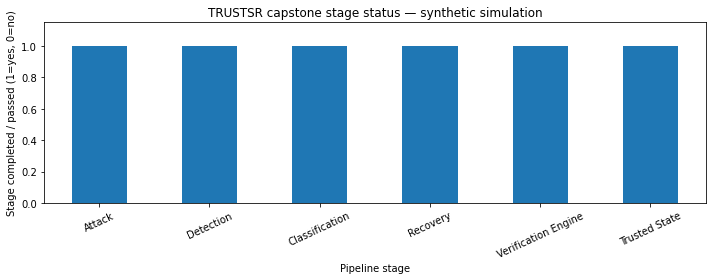

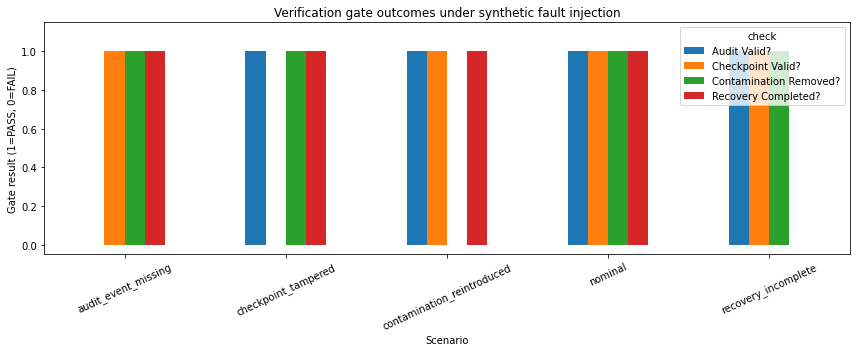

In [10]:
# Plot 1: stage completion trace (pipeline status, not real-world efficacy).
stage_codes = {"RECORDED":1, "EXECUTED":1, "PASS":1, "FAIL":0}
plot_pipeline = pipeline_df.copy()
plot_pipeline["passed_code"] = plot_pipeline["status"].map(stage_codes).fillna(0)
ax = plot_pipeline.plot(x="stage_name", y="passed_code", kind="bar", legend=False, figsize=(10,4))
ax.set_title("TRUSTSR capstone stage status — synthetic simulation")
ax.set_xlabel("Pipeline stage")
ax.set_ylabel("Stage completed / passed (1=yes, 0=no)")
ax.set_ylim(0, 1.15)
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

# Plot 2: verification gate outcomes for nominal and fault scenarios.
scenario_checks = []
for _, row in verification_df.iterrows():
    scenario_checks.append({"scenario":"nominal", "check":row["check"], "passed":int(row["passed"])})
for _, fault in fault_df.iterrows():
    # Re-run to get per-gate status for each injected fault.
    if fault["case"] == "checkpoint_tampered":
        v, d = verify_all(cp_bad, audit_events, recovery_record)
    elif fault["case"] == "audit_event_missing":
        v, d = verify_all(checkpoint, audit_bad, recovery_record)
    elif fault["case"] == "contamination_reintroduced":
        v, d = verify_all(checkpoint, audit_events, rec_bad)
    else:
        v, d = verify_all(checkpoint, audit_events, rec_incomplete)
    for _, gate in d.iterrows():
        scenario_checks.append({"scenario":fault["case"], "check":gate["check"], "passed":int(gate["passed"])})
gate_plot_df = pd.DataFrame(scenario_checks)
gate_pivot = gate_plot_df.pivot(index="scenario", columns="check", values="passed")
ax = gate_pivot.plot(kind="bar", figsize=(12,5))
ax.set_title("Verification gate outcomes under synthetic fault injection")
ax.set_xlabel("Scenario")
ax.set_ylabel("Gate result (1=PASS, 0=FAIL)")
ax.set_ylim(-0.05, 1.15)
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

print("Synthetic detector counts:", {"TP":tp, "FN":fn, "FP":fp})
print("Nominal verdict:", verdict, "| Fault cases rejected:", int(fault_df["verdict"].eq("FAIL").sum()), "/", len(fault_df))

## 11. Export CSV artifacts

In [11]:
exports = {
    "trustsr_capstone_attack_trace.csv": event_df,
    "trustsr_capstone_detection_results.csv": detection_df,
    "trustsr_capstone_classification.csv": classification_df,
    "trustsr_capstone_verification_gates.csv": verification_df.assign(scenario="nominal", final_verdict=verdict),
    "trustsr_capstone_fault_injection.csv": fault_df,
    "trustsr_capstone_pipeline_trace.csv": pipeline_df,
    "trustsr_capstone_gate_scenarios.csv": gate_plot_df,
}
for filename, frame in exports.items():
    frame.to_csv(filename, index=False)
    path = Path(filename)
    assert path.exists() and path.stat().st_size > 0
    print("Exported:", filename, "| rows:", len(frame), "| bytes:", path.stat().st_size)

assert verdict == "PASS"
assert state_2 == "Trusted"
assert fault_df["verdict"].eq("FAIL").all()
print("CAPSTONE ASSERTIONS PASSED — synthetic simulation only.")

Exported: trustsr_capstone_attack_trace.csv | rows: 4 | bytes: 367
Exported: trustsr_capstone_detection_results.csv | rows: 4 | bytes: 335
Exported: trustsr_capstone_classification.csv | rows: 4 | bytes: 382
Exported: trustsr_capstone_verification_gates.csv | rows: 4 | bytes: 377
Exported: trustsr_capstone_fault_injection.csv | rows: 4 | bytes: 207
Exported: trustsr_capstone_pipeline_trace.csv | rows: 6 | bytes: 604
Exported: trustsr_capstone_gate_scenarios.csv | rows: 20 | bytes: 812
CAPSTONE ASSERTIONS PASSED — synthetic simulation only.


## 12. Publication-ready interpretation

### Observed within this synthetic fixture
- The detector identified the declared malicious memory-write event: `FN = 0` for this one declared ground-truth attack event.
- The classifier labeled the injected artifact `Contaminated` and an artifact without sufficient provenance `Unknown`.
- Recovery restored the declared clean artifacts and left the unknown artifact unverified.
- The four-gate verifier returned `PASS` for the nominal fixture.
- All four fault-injection scenarios returned `FAIL`.
- The trust-state policy required the sequence `Contaminated → Recovered → Trusted`; negative controls blocked promotion when verification failed or evidence was absent.

### Interpretation boundary
These counts are properties of a hand-authored synthetic fixture. They are not estimates of real-world detection accuracy, recovery reliability, or security. The trusted checkpoint and signature validity are simulated flags; the audit log is an in-memory list; the ground-truth set is assumed complete.

### Suggested paper wording
“We implemented an end-to-end TRUSTSR prototype spanning synthetic attack simulation, detection, uncertainty-aware classification, selective checkpoint recovery, four-gate verification, and guarded trust-state reinstatement. In the defined synthetic fixture, the nominal path passed all verification gates and all four injected fault scenarios were rejected. These results establish implementation-level behavior against the encoded test cases only. Real-world effectiveness, cryptographic authenticity, and novelty relative to prior work remain to be evaluated.”

### Final checklist
- [ ] Run all cells in a fresh Colab runtime.
- [ ] Confirm nominal verification verdict is `PASS`.
- [ ] Confirm the guarded transition is `Contaminated → Recovered → Trusted`.
- [ ] Confirm all four injected faults return `FAIL`.
- [ ] Confirm seven CSV files are exported.
- [ ] Save the executed notebook and CSV outputs as the experiment record.
- [ ] Before making novelty claims, conduct a documented literature review and baseline comparison.